# 02 — Dataset Exploration (thesis Chapter 4)

**Inputs:** `data/raw/calfire/mapdataall.csv`, `data/raw/prescribed_burns/California_Fire_Perimeters_(all).geojson`,
`data/raw/boundaries/California_County_Boundaries.geojson`, `data/processed/monthly_data.csv`, `data/raw/noaa_climate/climate_data.xlsx`

**Produces:**
| Thesis item | Output |
|---|---|
| Tables 4.1–4.3 (descriptive statistics) | printed (LaTeX) |
| Fig 4.1 fires per month/year | `figures/rx_vs_wild.pdf` |
| Fig 4.2 fire size distributions | `figures/acres.pdf` |
| Fig 4.3 annual acres | `figures/rx_vs_wild_acres.pdf` |
| Figs 4.4–4.5 maps | `figures/rx_wild_map_2013_2016.png`, `figures/rx_wild_map_2017_2020.png` |
| Fig 4.6 climate boxplots (monthly data) | `figures/climate_bp.pdf` |
| Figs 4.13–4.14 chi-squared region × year | `figures/wildfire_chi.pdf`, `figures/rx_chi.pdf` |

**Notes for future work**
* This notebook rebuilds the wildfire table on its own (it does not read `prescribed_treatment_data_new_clean.csv`),
  so its row count (2,041) is before the final cleaning in 01 (1,992 rows).
* The Mann–Whitney tests here use the **monthly statewide** data (n = 120 months). Thesis **Table 4.4** reports
  different U values (e.g. 11277.5 for `precip < 1`) that could not be reproduced from any file in this repository;
  treat Table 4.4 as unverified.
* In the prescribed-fire chi-squared plot cell, `ax[0].set_ylim(...)` refers to an axis from an earlier figure
  (it should be `axs`), so those y-limits have no effect. Left unchanged so the figure matches the thesis.

In [1]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
plt.style.use("ggplot")
import numpy as np 
import matplotlib.dates as mdates
import os
import datetime
import xarray as xr
import rioxarray
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import math
import seaborn as sn 

from functions import *

# Dataset Exploration

Spatial statistics:
- R spatial model of co-regionalization - on different counties - look at if things happen differently between counties

Notes:
- 2 year lag on prescribed acres seems to have highest correlation
- prescribed burns might be more effective in humbolt
- chi squared question (county, years)
- 3 and 6 month prescribed burn increments have significant effect
- 5 km not significant - could be too small of a disance

to do:
- do county chi-squared, add treatment as chi-squared add year
- log linear - poisson regression - probability of fire in year, compare counties offset term - will give a rate of wildfire in each county per km, each row is wildfire
- spatial component - x closest, normalize by size of prescribed and distance

done:
- mixed effect model with county variable
- linear model for wildfires, soil moisture, etc previous month
- treatment analysis with non-parametric test
- initial county data analysis
- built data set for treatment analysis
- log transform
- build county datasets https://www.ncei.noaa.gov/access/monitoring/climate-at-a-glance/county/time-series

counties:
- sequoia national park -  Tulare County
- Humboldt County 

## Wildfires

In [2]:
df = pd.read_csv("data/raw/calfire/mapdataall.csv")
df["incident_date_created"] = pd.to_datetime(df["incident_date_created"].fillna(df["incident_date_extinguished"]))
df["year"] = df["incident_date_created"].dt.year
df["month"] =  df["incident_date_created"].dt.month

df = df.sort_values("incident_date_created", ascending=True)
df = df.loc[(df["year"].astype(int)>2012) & (df["year"].astype(int)<2023)].fillna(0).reset_index(drop=True)
df = df.loc[(df["incident_latitude"]>31) &(df["incident_latitude"]<43)].reset_index(drop=True)
df.at[1736,"incident_longitude"] = -119.1414610 

In [3]:
df

,incident_name,incident_is_final,incident_date_last_update,incident_date_created,incident_administrative_unit,incident_administrative_unit_url,incident_county,incident_location,incident_acres_burned,incident_containment,...,incident_id,incident_url,incident_date_extinguished,incident_dateonly_extinguished,incident_dateonly_created,is_active,calfire_incident,notification_desired,year,month
0,River Fire,Y,2022-10-24T11:39:23Z,2013-02-24 08:16:00+00:00,CAL FIRE San Bernardino Unit,0.0,Inyo,"south of Narrow Gauge Rd & north of Hwy 136, e...",407.0,100.0,...,094719ba-a47b-4abb-9ec5-a506b2b9fd23,https://incidents.fire.ca.gov/incidents/2013/2...,2013-02-28T20:00:00Z,2013-02-28,2013-02-24,N,True,False,2013,2
1,Fawnskin Fire,Y,2013-04-22T09:00:00Z,2013-04-20 17:30:00+00:00,San Bernardino National Forest,0.0,San Bernardino,"west of Delamar Mountain, north of the communi...",30.0,100.0,...,58f89ff8-bd3e-4355-b1c0-8fa05c747d3f,https://incidents.fire.ca.gov/incidents/2013/4...,2013-04-22T09:00:00Z,2013-04-22,2013-04-20,N,False,False,2013,4
2,Gold Fire,Y,2013-05-01T07:00:00Z,2013-04-30 12:59:00+00:00,CAL FIRE Madera-Mariposa-Merced Unit,0.0,Madera,Between Road 210 and Road 200 near Fine Gold C...,274.0,100.0,...,357ffc13-bef9-48eb-810f-c5de851972eb,https://incidents.fire.ca.gov/incidents/2013/4...,2013-05-01T07:00:00Z,2013-05-01,2013-04-30,N,True,False,2013,4
3,Silverado Fire,Y,2013-05-01T17:15:00Z,2013-04-30 23:44:00+00:00,CAL FIRE Sonoma-Lake-Napa Unit,0.0,Napa,"7300 block of Silverado Trail, north of Napa",75.0,100.0,...,d8d1c943-7b5d-4885-9043-f41075d6eded,https://incidents.fire.ca.gov/incidents/2013/4...,2013-05-01T17:15:00Z,2013-05-01,2013-04-30,N,True,False,2013,4
4,Yellow Fire,Y,2013-05-03T06:15:00Z,2013-05-01 02:01:00+00:00,CAL FIRE Sonoma-Lake-Napa Unit,0.0,Sonoma,Hwy 128 & Yellow Jacket Ranch Rd in Knights Va...,125.0,100.0,...,64e4f81e-d872-44c4-ba8d-111fa77124ba,https://incidents.fire.ca.gov/incidents/2013/5...,2013-05-03T06:15:00Z,2013-05-03,2013-05-01,N,True,False,2013,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2046,Irie Fire,N,2022-10-27T11:36:59Z,2022-09-21 07:29:00+00:00,Bureau of Indian Affairs,0.0,Tulare,"Gibbons Rd. and Gibbons Canyon, east of Porter...",0.0,0.0,...,cad849b4-be9c-4a47-889d-a1c1bcf2c085,https://incidents.fire.ca.gov/incidents/2022/9...,0,0,2022-09-21,N,False,False,2022,9
2047,Manzanita Fire,N,2022-10-27T11:36:47Z,2022-09-23 15:23:00+00:00,San Bernardino National Forest,0.0,San Bernardino,"Manzanita Flats, North of San Bernardino",0.0,0.0,...,70bfeb43-3af8-4aa8-847c-07f0869d6f6d,https://incidents.fire.ca.gov/incidents/2022/9...,0,0,2022-09-23,N,False,False,2022,9
2048,97 Fire,Y,2022-09-29T07:35:17Z,2022-09-27 08:54:50+00:00,CAL FIRE Siskiyou Unit,0.0,Siskiyou,"Quarry Road and Quarry Lance, Lake Shastina",30.0,100.0,...,a5373b17-81bc-4a24-a844-148cb5de6b10,https://incidents.fire.ca.gov/incidents/2022/9...,0,0,2022-09-27,N,True,False,2022,9
2049,Howard Fire,N,2022-10-27T11:53:52Z,2022-10-08 15:42:50+00:00,Los Padres National Forest,0.0,Ventura,Rose Valley Rd and Gene Marshall-Piedra Blanca...,0.0,0.0,...,a139a767-908f-4275-9314-f3fb47bd9155,https://incidents.fire.ca.gov/incidents/2022/1...,0,0,2022-10-08,N,False,False,2022,10


In [4]:
np.argmax(df["incident_longitude"])
df.at[np.argmax(df["incident_longitude"]),"incident_longitude"] = - df.at[np.argmax(df["incident_longitude"]),"incident_longitude"]

In [5]:
df = df.loc[(df["incident_longitude"]>-125) &(df["incident_longitude"]<-114)].reset_index(drop=True)

In [6]:
df

,incident_name,incident_is_final,incident_date_last_update,incident_date_created,incident_administrative_unit,incident_administrative_unit_url,incident_county,incident_location,incident_acres_burned,incident_containment,...,incident_id,incident_url,incident_date_extinguished,incident_dateonly_extinguished,incident_dateonly_created,is_active,calfire_incident,notification_desired,year,month
0,River Fire,Y,2022-10-24T11:39:23Z,2013-02-24 08:16:00+00:00,CAL FIRE San Bernardino Unit,0.0,Inyo,"south of Narrow Gauge Rd & north of Hwy 136, e...",407.0,100.0,...,094719ba-a47b-4abb-9ec5-a506b2b9fd23,https://incidents.fire.ca.gov/incidents/2013/2...,2013-02-28T20:00:00Z,2013-02-28,2013-02-24,N,True,False,2013,2
1,Fawnskin Fire,Y,2013-04-22T09:00:00Z,2013-04-20 17:30:00+00:00,San Bernardino National Forest,0.0,San Bernardino,"west of Delamar Mountain, north of the communi...",30.0,100.0,...,58f89ff8-bd3e-4355-b1c0-8fa05c747d3f,https://incidents.fire.ca.gov/incidents/2013/4...,2013-04-22T09:00:00Z,2013-04-22,2013-04-20,N,False,False,2013,4
2,Gold Fire,Y,2013-05-01T07:00:00Z,2013-04-30 12:59:00+00:00,CAL FIRE Madera-Mariposa-Merced Unit,0.0,Madera,Between Road 210 and Road 200 near Fine Gold C...,274.0,100.0,...,357ffc13-bef9-48eb-810f-c5de851972eb,https://incidents.fire.ca.gov/incidents/2013/4...,2013-05-01T07:00:00Z,2013-05-01,2013-04-30,N,True,False,2013,4
3,Silverado Fire,Y,2013-05-01T17:15:00Z,2013-04-30 23:44:00+00:00,CAL FIRE Sonoma-Lake-Napa Unit,0.0,Napa,"7300 block of Silverado Trail, north of Napa",75.0,100.0,...,d8d1c943-7b5d-4885-9043-f41075d6eded,https://incidents.fire.ca.gov/incidents/2013/4...,2013-05-01T17:15:00Z,2013-05-01,2013-04-30,N,True,False,2013,4
4,Yellow Fire,Y,2013-05-03T06:15:00Z,2013-05-01 02:01:00+00:00,CAL FIRE Sonoma-Lake-Napa Unit,0.0,Sonoma,Hwy 128 & Yellow Jacket Ranch Rd in Knights Va...,125.0,100.0,...,64e4f81e-d872-44c4-ba8d-111fa77124ba,https://incidents.fire.ca.gov/incidents/2013/5...,2013-05-03T06:15:00Z,2013-05-03,2013-05-01,N,True,False,2013,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2039,Irie Fire,N,2022-10-27T11:36:59Z,2022-09-21 07:29:00+00:00,Bureau of Indian Affairs,0.0,Tulare,"Gibbons Rd. and Gibbons Canyon, east of Porter...",0.0,0.0,...,cad849b4-be9c-4a47-889d-a1c1bcf2c085,https://incidents.fire.ca.gov/incidents/2022/9...,0,0,2022-09-21,N,False,False,2022,9
2040,Manzanita Fire,N,2022-10-27T11:36:47Z,2022-09-23 15:23:00+00:00,San Bernardino National Forest,0.0,San Bernardino,"Manzanita Flats, North of San Bernardino",0.0,0.0,...,70bfeb43-3af8-4aa8-847c-07f0869d6f6d,https://incidents.fire.ca.gov/incidents/2022/9...,0,0,2022-09-23,N,False,False,2022,9
2041,97 Fire,Y,2022-09-29T07:35:17Z,2022-09-27 08:54:50+00:00,CAL FIRE Siskiyou Unit,0.0,Siskiyou,"Quarry Road and Quarry Lance, Lake Shastina",30.0,100.0,...,a5373b17-81bc-4a24-a844-148cb5de6b10,https://incidents.fire.ca.gov/incidents/2022/9...,0,0,2022-09-27,N,True,False,2022,9
2042,Howard Fire,N,2022-10-27T11:53:52Z,2022-10-08 15:42:50+00:00,Los Padres National Forest,0.0,Ventura,Rose Valley Rd and Gene Marshall-Piedra Blanca...,0.0,0.0,...,a139a767-908f-4275-9314-f3fb47bd9155,https://incidents.fire.ca.gov/incidents/2022/1...,0,0,2022-10-08,N,False,False,2022,10


In [7]:
county_regions = {
    "North Coast": ['Del Norte', 'Humboldt', 'Mendocino', "Sonoma", "Lake", "Napa", "Marin", "Trinity"],
    "Shasta Cascades": ['Siskiyou', "Trinity", "Shasta", "Lassen", "Modoc",
                        'Tehama', "Butte", "Plumas", "State of Oregon"],
    "Central Valley": ["Glenn", "Colusa", "Sutter","Yolo", "Sacramento", "Solano", "Fresno", "Kern", "Kings",
                       "Madera", "Merced", "Placer", "San Joaquin", "Tehama", "Yuba", "Stanislaus"],
    "Sierras": ["Alpine", "Amador", "Calaveras", "El Dorado", "Inyo", "Mariposa", "Mono", "Nevada", "Plumas", "Sierra", "Tulare",
                "Tuolumne", "State of Nevada"],
    "Central Coast": ["Contra Costa", "Alameda", "San Fransisco", "San Mateo", "Santa Clara",
                      "Santa Cruz", "San Benito", "Monterey", "San Luis Obispo", "Santa Barbara", "Ventura"],
    "South Coast": ["Los Angeles", "Orange", "San Diego"],
    "Desert": ["Riverside", "San Bernardino", "Imperial", "Mexico"],
    "Multiple": ["multiple"]
}

In [8]:
# df = df.dropna(subset=["incident_county"]).reset_index(drop=True)
# df = df.loc[df["incident_county"]!=0].reset_index(drop=True)
# fill missing counties
county_boundary = gpd.read_file("data/raw/boundaries/California_County_Boundaries.geojson")
df["county"] = [county_boundary.loc[county_boundary["geometry"].contains(Point(df.at[i,"incident_longitude"], df.at[i,"incident_latitude"]))].reset_index(drop=True).at[0,"COUNTY_NAME"] 
                if len(county_boundary.loc[county_boundary["geometry"].contains(Point(df.at[i,"incident_longitude"], df.at[i,"incident_latitude"]))]) > 0 
                else "none" 
                for i in range(len(df))]
df["county_new"] = [df.at[i,"incident_county"] if df.at[i,"incident_county"]!=0 else df.at[i, "county"] for i in range(len(df))]

In [9]:
df["county_new"] = [df.at[i,"incident_county"] if df.at[i,"incident_county"]!=0 else df.at[i, "county"] for i in range(len(df))]

In [10]:
df["county_new"].value_counts().index

Index(['Riverside', 'San Diego', 'San Luis Obispo', 'Butte', 'Siskiyou',
       'Shasta', 'Kern', 'San Bernardino', 'Fresno', 'Los Angeles', 'Tehama',
       'Monterey', 'Lassen', 'Tulare', 'Lake', 'Madera', 'Santa Clara',
       'El Dorado', 'Modoc', 'Contra Costa', 'Mendocino', 'Mariposa',
       'Alameda', 'Santa Barbara', 'Humboldt', 'Tuolumne', 'Calaveras', 'Yuba',
       'Placer', 'Ventura', 'Solano', 'Napa', 'Nevada', 'San Benito',
       'Trinity', 'Stanislaus', 'Merced', 'Sonoma', 'Plumas', 'Sacramento',
       'Orange', 'Inyo', 'Amador', 'Yolo', 'Glenn', 'Santa Cruz', 'Mono',
       'San Joaquin', 'Marin', 'Kings', 'Colusa', 'Del Norte', 'Sierra',
       'Alpine', 'San Mateo', 'Napa, Sonoma', 'Sutter', 'none', 'Imperial',
       'Shasta, Trinity', 'Monterey, San Luis Obispo', 'El Dorado, Placer',
       'Shasta, Tehama', 'State of Nevada', 'Fresno, Madera',
       'San Bernardino, Riverside',
       'Mendocino, Humboldt, Trinity, Tehama, Glenn, Lake, Colusa',
       'Napa, So

In [11]:
df = df.loc[df["county_new"]!="none"].reset_index(drop=True)

In [12]:
df["county_new"] = ["multiple" if len(str(county).split(","))>1 else county for county in df["county_new"]]
regions_per_county = {v: k for k, val in county_regions.items() for v in val}
df["region"] = [regions_per_county[county] for county in df["county_new"].to_list()]

In [13]:
print(df.describe().drop(["incident_containment", "incident_administrative_unit_url"], axis=1).round(3).to_latex())

\begin{tabular}{lrrrrr}
\toprule
 & incident_acres_burned & incident_longitude & incident_latitude & year & month \\
\midrule
count & 2041.000000 & 2041.000000 & 2041.000000 & 2041.000000 & 2041.000000 \\
mean & 5038.136000 & -120.281000 & 37.293000 & 2017.960000 & 7.233000 \\
std & 39490.062000 & 2.022000 & 2.582000 & 2.417000 & 1.821000 \\
min & 0.000000 & -124.200000 & 32.558000 & 2013.000000 & 1.000000 \\
25% & 35.000000 & -121.854000 & 34.919000 & 2017.000000 & 6.000000 \\
50% & 100.000000 & -120.705000 & 37.494000 & 2018.000000 & 7.000000 \\
75% & 424.000000 & -118.739000 & 39.355000 & 2020.000000 & 8.000000 \\
max & 1032648.000000 & -114.484000 & 42.048000 & 2022.000000 & 12.000000 \\
\bottomrule
\end{tabular}



In [14]:
df[['incident_county', "region", 'incident_type', 'incident_administrative_unit']].describe()

,incident_county,region,incident_type,incident_administrative_unit
count,2041,2041,2041,2041
unique,97,8,4,659
top,Riverside,Central Valley,0,CAL FIRE Santa Clara Unit
freq,178,433,1217,79


In [15]:
plt.figure()
hist, bins, _ = plt.hist(df["incident_acres_burned"].tolist())
plt.xscale('log')
plt.title("Acres Burned per Wildfire")
plt.xlabel("log(Acres Burned)")
plt.ylabel("log(Frequency)")
plt.show()

<Figure size 640x480 with 1 Axes>

In [16]:
# fig = px.scatter_geo(df, lat="incident_latitude", lon="incident_longitude", scope='usa', animation_frame="year", size="incident_acres_burned")
# fig.show()

## Prescribed Fires

In [17]:
import geopandas as gpd
gdf = gpd.read_file("data/raw/prescribed_burns/California_Fire_Perimeters_(all).geojson")

In [18]:
gdf["START_DATE"] = pd.to_datetime(gdf["START_DATE"], errors = 'coerce')

In [19]:
gdf["START_DATE"] = gdf["START_DATE"].fillna(pd.to_datetime(gdf["END_DATE"],  errors = 'coerce'))

In [20]:
gdf = gdf.dropna(subset=["START_DATE"])

In [21]:
gdf = gdf.sort_values('START_DATE', ascending=True)

In [22]:
gdf["year"] = gdf["START_DATE"].dt.year

In [23]:
gdf["lon_center"] = gdf["geometry"].centroid.x
gdf["lat_center"] = gdf["geometry"].centroid.y
gdf["YEAR_"] = gdf["YEAR_"].astype(int)
gdf = gdf.fillna(0)

/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35554/344453164.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf["lon_center"] = gdf["geometry"].centroid.x
/var/folders/cn/5p5n6ztx4310_zhlpq83ldym0000gn/T/ipykernel_35554/344453164.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf["lat_center"] = gdf["geometry"].centroid.y


In [24]:
gdf = gdf.reset_index(drop=True)

In [25]:
gdf["acres_decimal"] = [convert_acres_degrees(gdf.at[i,"TREATED_AC"], gdf.at[i, "lat_center"]) for i in range(len(gdf))]
df["acres_decimal"] = [convert_acres_degrees(df.at[i,"incident_acres_burned"], df.at[i, "incident_latitude"]) for i in range(len(df))]

In [26]:
# calculated the county for each 
county_boundary = gpd.read_file("data/raw/boundaries/California_County_Boundaries.geojson")
gdf["county"] = [county_boundary.loc[county_boundary["geometry"].contains(Point(gdf.at[i,"lon_center"], gdf.at[i,"lat_center"]))].reset_index(drop=True).at[0,"COUNTY_NAME"] for i in range(len(gdf))]
gdf["region"] = [regions_per_county[county] for county in gdf["county"].to_list()]

In [27]:
gdf = gdf.set_index("START_DATE")
gdf["year"] = gdf.index.year
gdf["month"] = gdf.index.month
gdf = gdf.loc['2013-01-01':'2022-12-31']

In [28]:
gdf[["TREATED_AC", "lat_center", "lon_center", "year", "month"]].describe().round(3)

,TREATED_AC,lat_center,lon_center,year,month
count,4123.000,4123.000,4123.000,4123.000,4123.000
mean,95.359,38.854,-120.792,2019.028,7.041
std,343.280,2.360,1.775,2.152,3.870
min,0.000,32.583,-124.359,2013.000,1.000
25%,4.076,37.340,-121.992,2018.000,4.000
50%,22.214,39.384,-120.863,2019.000,6.000
75%,76.000,40.774,-119.879,2020.000,11.000
max,7006.000,41.999,-115.827,2022.000,12.000


In [29]:
gdf[["county", "region"]].describe().round(3)

,county,region
count,4123,4123
unique,51,7
top,Siskiyou,Shasta Cascades
freq,624,1319


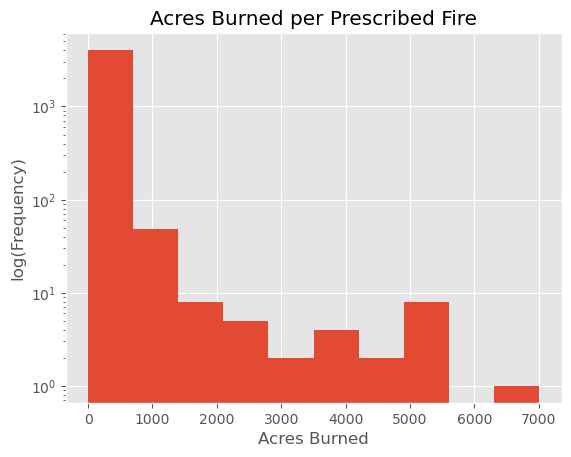

In [30]:
plt.figure()
hist, bins, _ = plt.hist(gdf["TREATED_AC"].tolist(), log=True)
plt.title("Acres Burned per Prescribed Fire")
plt.xlabel("Acres Burned")
plt.ylabel("log(Frequency)")
plt.show()

In [31]:
# fig = px.scatter_geo(gdf, lat="lat_center", lon="lon_center", scope='usa', animation_frame="year", size="rx_acres")
# fig.show()

# Prescribed vs Wildland

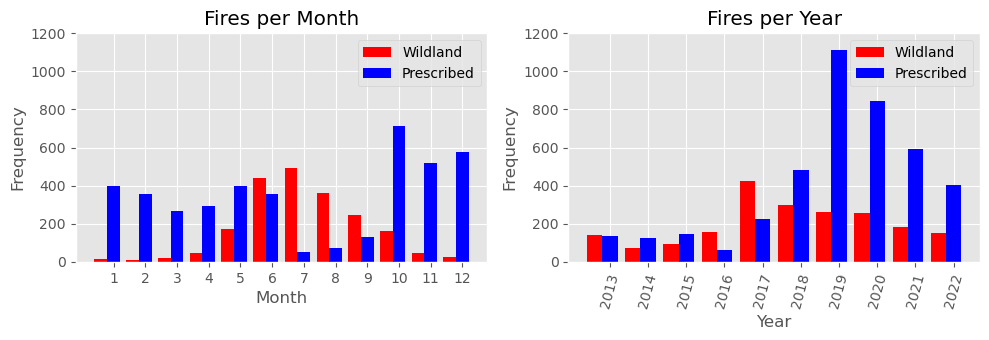

In [32]:
fig, ax = plt.subplots(1,2, figsize=(10,3.5))
x = np.arange(len(df["month"].value_counts()))  # the label locations
width = 0.4
ax[0].bar(x, list(df["month"].value_counts().sort_index().values), width, color="red", label="Wildland")
ax[0].bar(x+width, list(gdf["month"].value_counts().sort_index().values), width, color="blue", label="Prescribed")
ax[0].set_xticks(x + width, list(df["month"].value_counts().sort_index().index))
ax[0].set_ylim([0, 1200])
ax[0].set_title("Fires per Month")
ax[0].set_xlabel("Month")
ax[0].set_ylabel("Frequency")
ax[0].legend()

x = np.arange(len(df["year"].value_counts()))  # the label locations
width = 0.4
ax[1].bar(x, list(df["year"].value_counts().sort_index().values), width, color="red", label="Wildland")
ax[1].bar(x+width, list(gdf["year"].value_counts().sort_index().values), width, color="blue", label="Prescribed")
ax[1].set_xticks(x + width, list(df["year"].value_counts().sort_index().index), rotation=75)
ax[1].set_ylim([0, 1200])
ax[1].set_title("Fires per Year")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Frequency")
ax[1].legend()
plt.tight_layout()
plt.savefig("figures/rx_vs_wild.pdf")
plt.show()


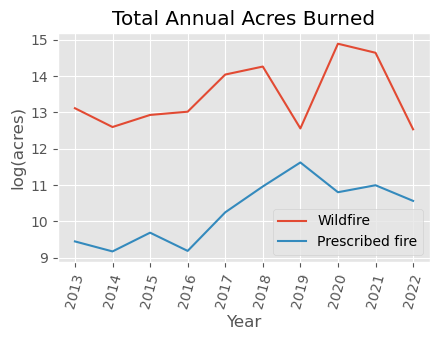

In [33]:
years = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
wf_sum = []
rx_sum = []
for year in years:
    wf_sum.append(np.log(df.loc[df["year"]==year]["incident_acres_burned"].sum()))
    rx_sum.append(np.log(gdf.loc[gdf["year"]==year]["TREATED_AC"].sum()))

fig = plt.figure(figsize=(4.5, 3.5))
plt.plot(years, wf_sum, label="Wildfire")
plt.plot(years, rx_sum, label="Prescribed fire")
plt.title("Total Annual Acres Burned")
plt.ylabel("log(acres)")
plt.xlabel("Year")
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xticks(ticks=years, labels=years, rotation=75)
plt.legend()
plt.tight_layout()
plt.savefig("figures/rx_vs_wild_acres.pdf")
plt.show()
    

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


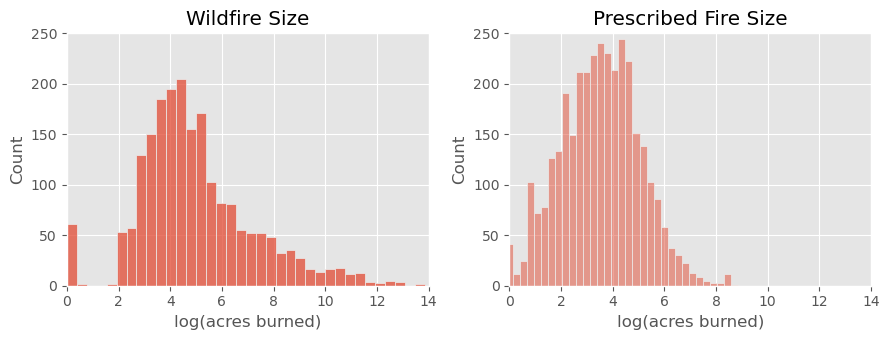

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(9,3.5))
sn.histplot(np.log(df['incident_acres_burned'].replace(0, np.nan)).replace(np.nan, 0), ax=axs[0], legend=False)
axs[0].set_xlabel("log(acres burned)")
axs[0].set_title("Wildfire Size")
axs[0].set_ylim([0, 250])
axs[0].set_xlim([0, 14])
sn.histplot(np.log(gdf[["TREATED_AC"]]), ax=axs[1], legend=False)
axs[1].set_xlabel("log(acres burned)")
axs[1].set_ylim([0, 250])
axs[1].set_xlim([0, 14])
axs[1].set_title("Prescribed Fire Size")
plt.tight_layout()
plt.savefig("figures/acres.pdf")
plt.show()

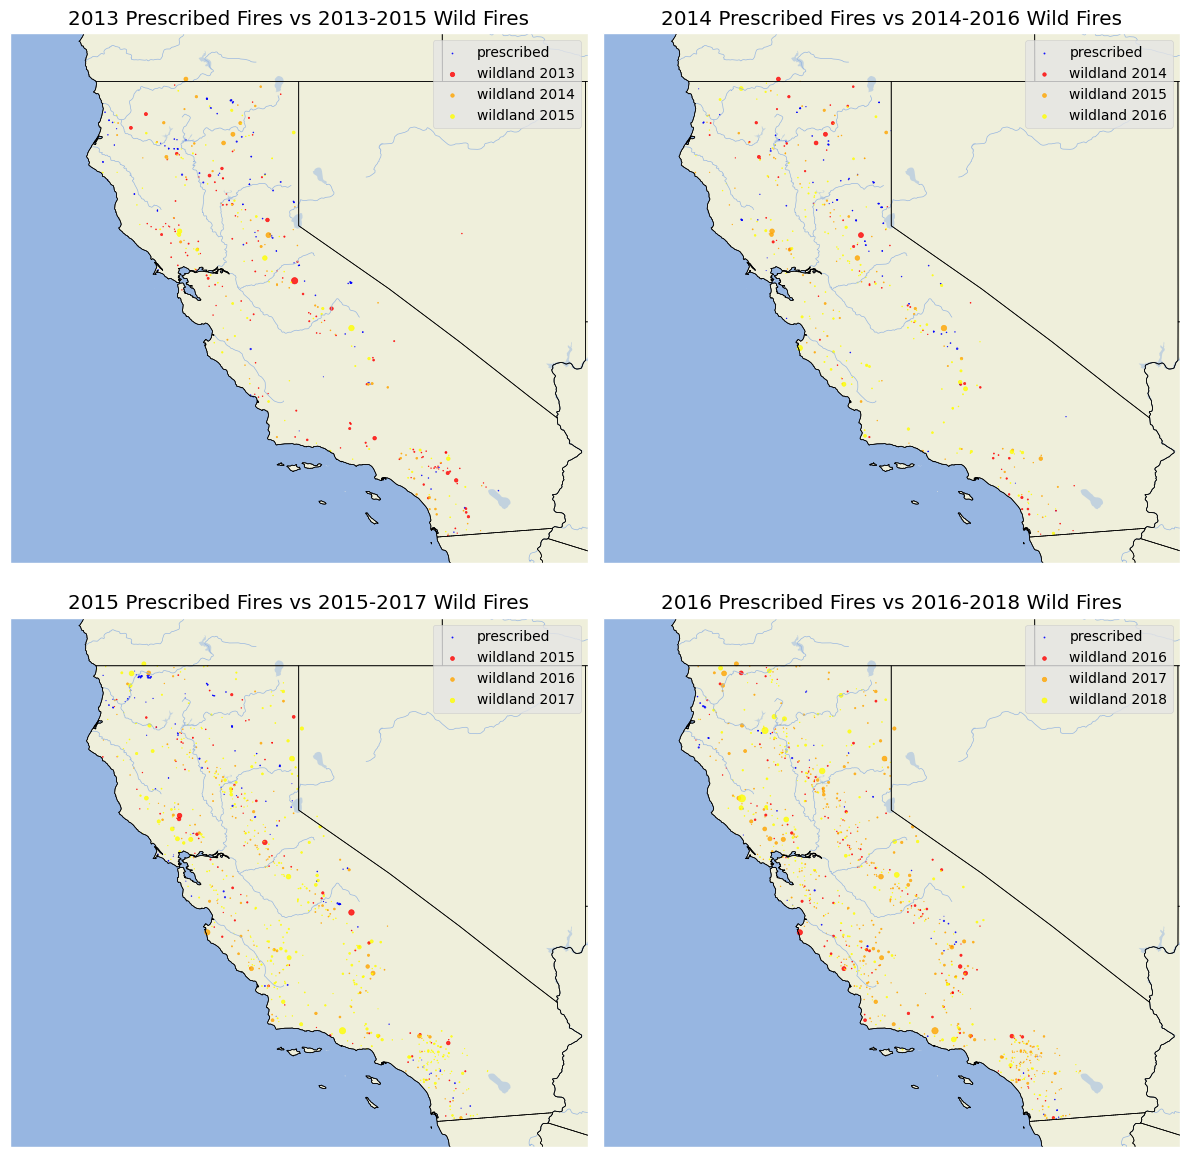

In [35]:
fig = plot_rx_wild_fires_multi_year(prescribed=gdf, wild=df, years=[2013, 2014, 2015, 2016, 2017, 2018, 2019], years_to_plot=[2013, 2014, 2015, 2016])
fig.savefig("figures/rx_wild_map_2013_2016.png", dpi=200)  # PNG: the vector PDF is ~30 MB

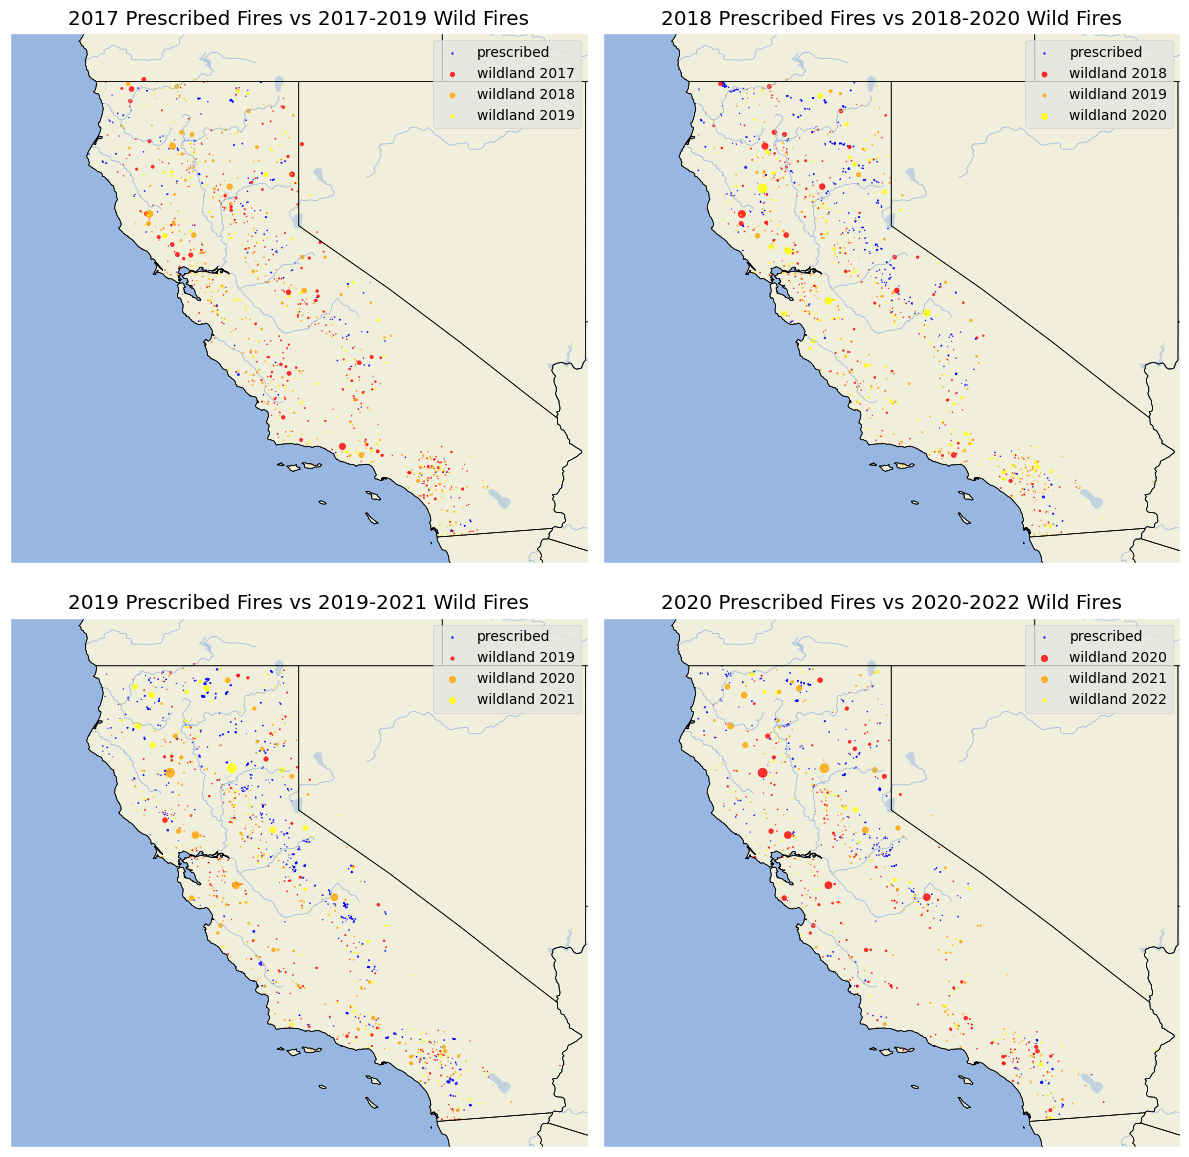

In [36]:
fig = plot_rx_wild_fires_multi_year(prescribed=gdf, wild=df, years=[2017, 2018, 2019, 2020, 2021, 2022], years_to_plot=[2017, 2018, 2019, 2020])
fig.savefig("figures/rx_wild_map_2017_2020.png", dpi=200)  # PNG: the vector PDF is ~30 MB

In [37]:
#_ = plot_rx_wild_fires_singles(prescribed=gdf, wild=df, years=[2016, 2017, 2018, 2019, 2020, 2021, 2022])

In [38]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2016, wild_years=[2016, 2017, 2018, 2019])

In [39]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2017, wild_years=[2017, 2018, 2019, 2020])

In [40]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2018, wild_years=[2018, 2019, 2020, 2021])

In [41]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2019, wild_years=[2019, 2020, 2021, 2022])

In [42]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2020, wild_years=[2020, 2021, 2022])

In [43]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2021, wild_years=[2021, 2022])

In [44]:
#_ = plot_rx_wild_fires(prescribed=gdf, wild=df, prescribed_year=2022, wild_years=[2022])

## Climate

## Combined Dataset

In [45]:
data = pd.read_csv("data/processed/monthly_data.csv", index_col=0)
data.index = pd.to_datetime(data.index)

In [46]:
data

,rx_acres,rx_acres_3_month,rx_acres_6_month,rx_acres_9_month,rx_acres_12_month,incident_acres_burned,cdd,hdd,pcp,pdsi,phdi,pmdi,tavg,tmax,tmin,zndx
2013-01-31 00:00:00+00:00,548.078092,8494.236071,11597.795940,15273.78719,17490.87933,0,0,576,1.19,-0.80,-0.80,-0.80,42.1,53.2,31.0,-2.39
2013-02-28 00:00:00+00:00,319.037923,8494.236071,8570.236071,14849.94974,17091.93358,407,0,476,0.58,-1.66,-1.66,-1.66,45.3,57.6,33.1,-2.84
2013-03-31 00:00:00+00:00,403.706443,7236.576912,9361.352086,14621.07384,16361.41022,0,8,317,1.33,-2.43,-2.43,-2.43,53.8,66.5,41.0,-2.84
2013-04-30 00:00:00+00:00,1892.390845,2613.074676,9361.352086,12464.91196,16140.90321,379,22,219,0.71,-2.83,-2.83,-2.83,58.2,71.7,44.7,-1.95
2013-05-31 00:00:00+00:00,2108.507682,3163.213302,11657.449370,11733.44937,18013.16304,54916,63,112,0.62,-2.98,-2.98,-2.98,63.8,77.5,50.1,-1.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-08-31 00:00:00+00:00,15.000000,11297.365690,23227.702390,35863.81239,36765.01239,31789,340,0,0.40,-4.78,-4.78,-4.78,78.4,92.9,64.0,-0.41
2022-09-30 00:00:00+00:00,1327.228941,10166.571040,18087.909940,29206.40239,36740.71239,131059,271,3,0.83,-4.04,-4.04,-3.70,73.8,87.6,60.1,0.75
2022-10-31 00:00:00+00:00,11740.186050,7086.969981,14552.246750,26023.88133,37846.94133,50,63,86,0.16,-4.49,-4.49,-4.49,63.7,77.6,49.7,-2.61
2022-11-30 00:00:00+00:00,1984.361678,1435.028941,12639.594630,24569.93133,37206.04133,0,0,431,2.00,-4.24,-4.24,-4.24,46.8,58.4,35.2,-0.63


## Scatterplots

In [47]:
data.columns

Index(['rx_acres', 'rx_acres_3_month', 'rx_acres_6_month', 'rx_acres_9_month',
       'rx_acres_12_month', 'incident_acres_burned', 'cdd', 'hdd', 'pcp',
       'pdsi', 'phdi', 'pmdi', 'tavg', 'tmax', 'tmin', 'zndx'],
      dtype='object')

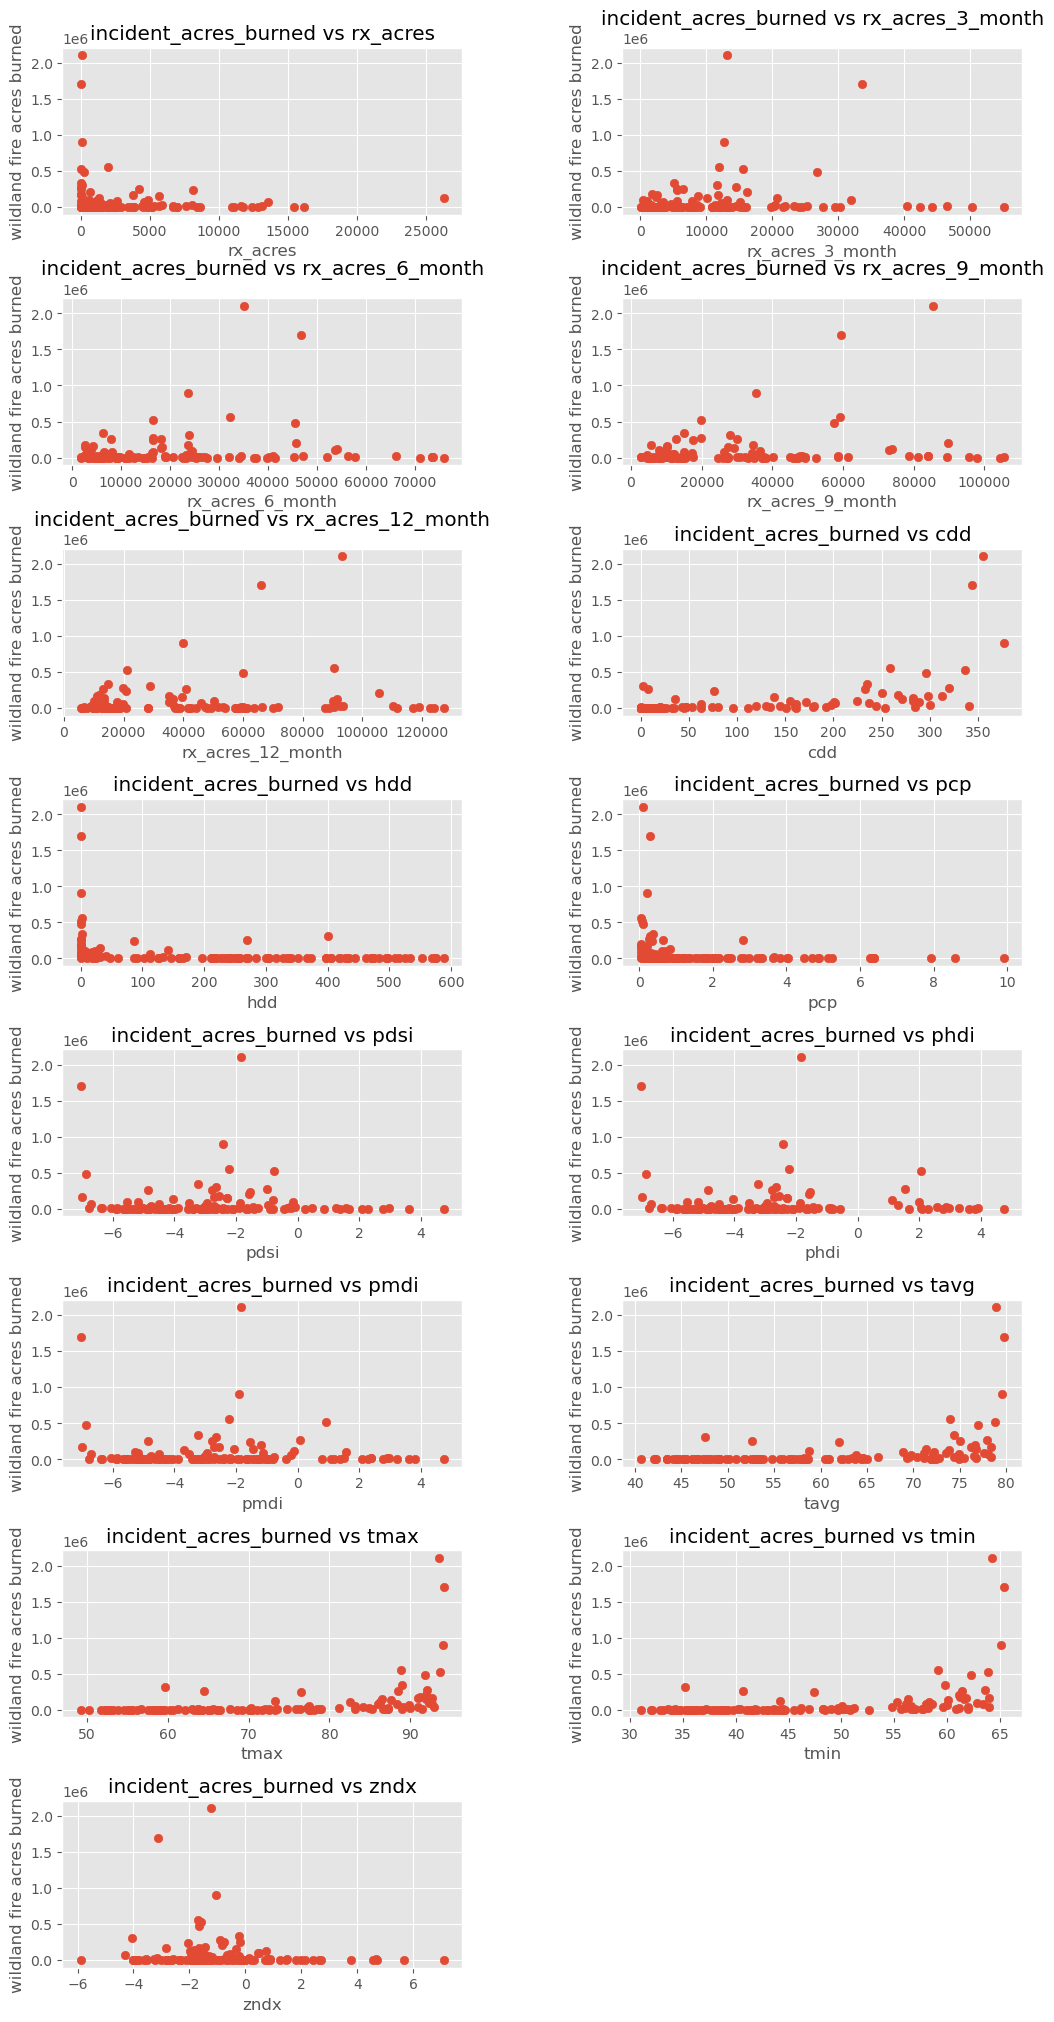

In [48]:
predictors = [ 'rx_acres', 'rx_acres_3_month', 'rx_acres_6_month','rx_acres_9_month', 'rx_acres_12_month', 'cdd', 'hdd', 'pcp', 'pdsi',
       'phdi', 'pmdi', 'tavg', 'tmax', 'tmin', 'zndx']
target = 'incident_acres_burned'
_ = scatter_plots(data, target, predictors)

## Statistics

### Wildland vs Prescribed

mwu / wilcoxson rank-signed

In [49]:
data["prescribed_10000"] = data['rx_acres']>10000
data["prescribed_8000"] = data['rx_acres']>8000
data["prescribed_5000"] = data['rx_acres']>5000

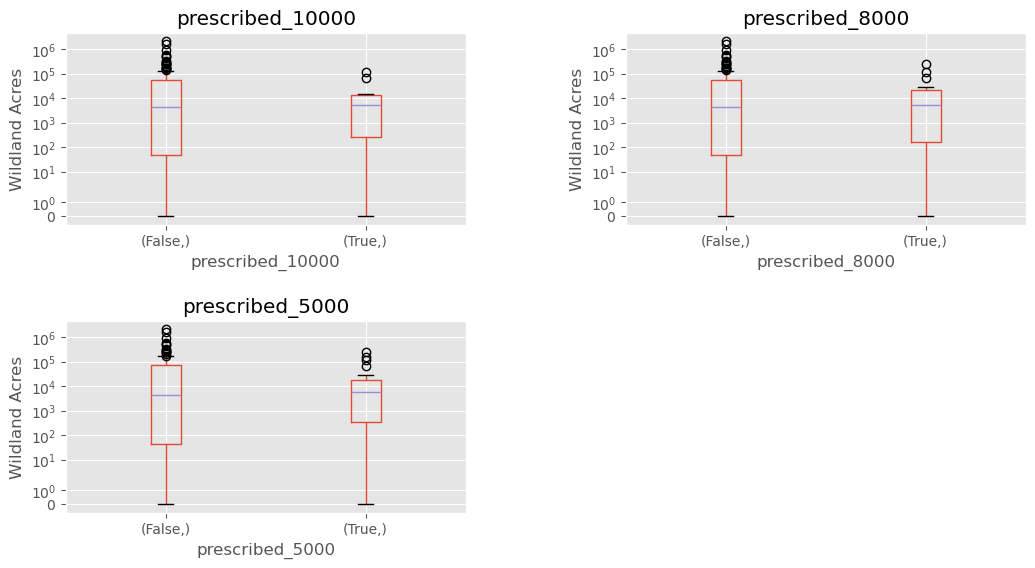

In [50]:
_ = build_boxplots(data, target, predictors = ["prescribed_10000","prescribed_8000", "prescribed_5000" ])

In [51]:
mwu, t = run_stats(data, "incident_acres_burned", ["prescribed_5000", "prescribed_8000", "prescribed_10000"])
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_5000,MWU,1198.0,two-sided,0.881,0.020,0.490
prescribed_8000,MWU,761.0,two-sided,0.836,0.034,0.483
prescribed_10000,MWU,573.5,two-sided,0.816,0.043,0.478


### Wildland vs Drought index

In [52]:
data["pdsi<0"] = data['pdsi']<0
data["pdsi<-2"] = data['pdsi']<-2

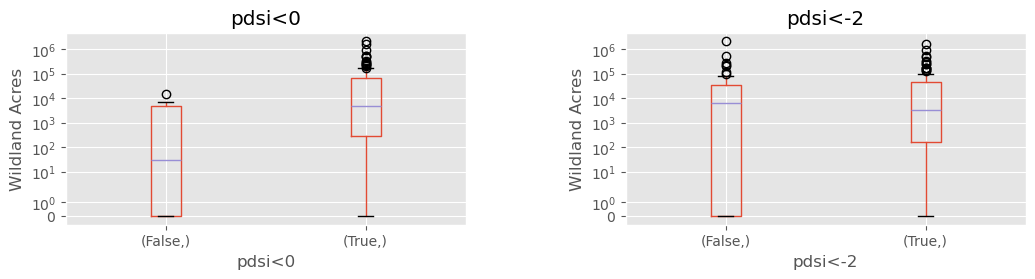

In [53]:
_ = build_boxplots(data, target, predictors = ["pdsi<0","pdsi<-2"])

In [54]:
mwu, t = run_stats(data, "incident_acres_burned", ["pdsi<0", "pdsi<-2"])
display(mwu.round(3))
display(t)

,,U-val,alternative,p-val,RBC,CLES
pdsi<0,MWU,1007.5,two-sided,0.008,-0.449,0.724
pdsi<-2,MWU,1511.5,two-sided,1.000,0.000,0.500


,,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
pdsi<0,T-test,3.412967,106.440231,two-sided,0.000910,"[39644.55, 149532.5]",0.348479,32.594,0.217621
pdsi<-2,T-test,-0.446340,47.425776,two-sided,0.657383,"[-159063.85, 101286.78]",0.105927,0.23,0.082430


# Log-scale target

In [55]:
data["log_acres"] = np.log(data['incident_acres_burned'].replace(0, np.nan)).replace(np.nan, 0)

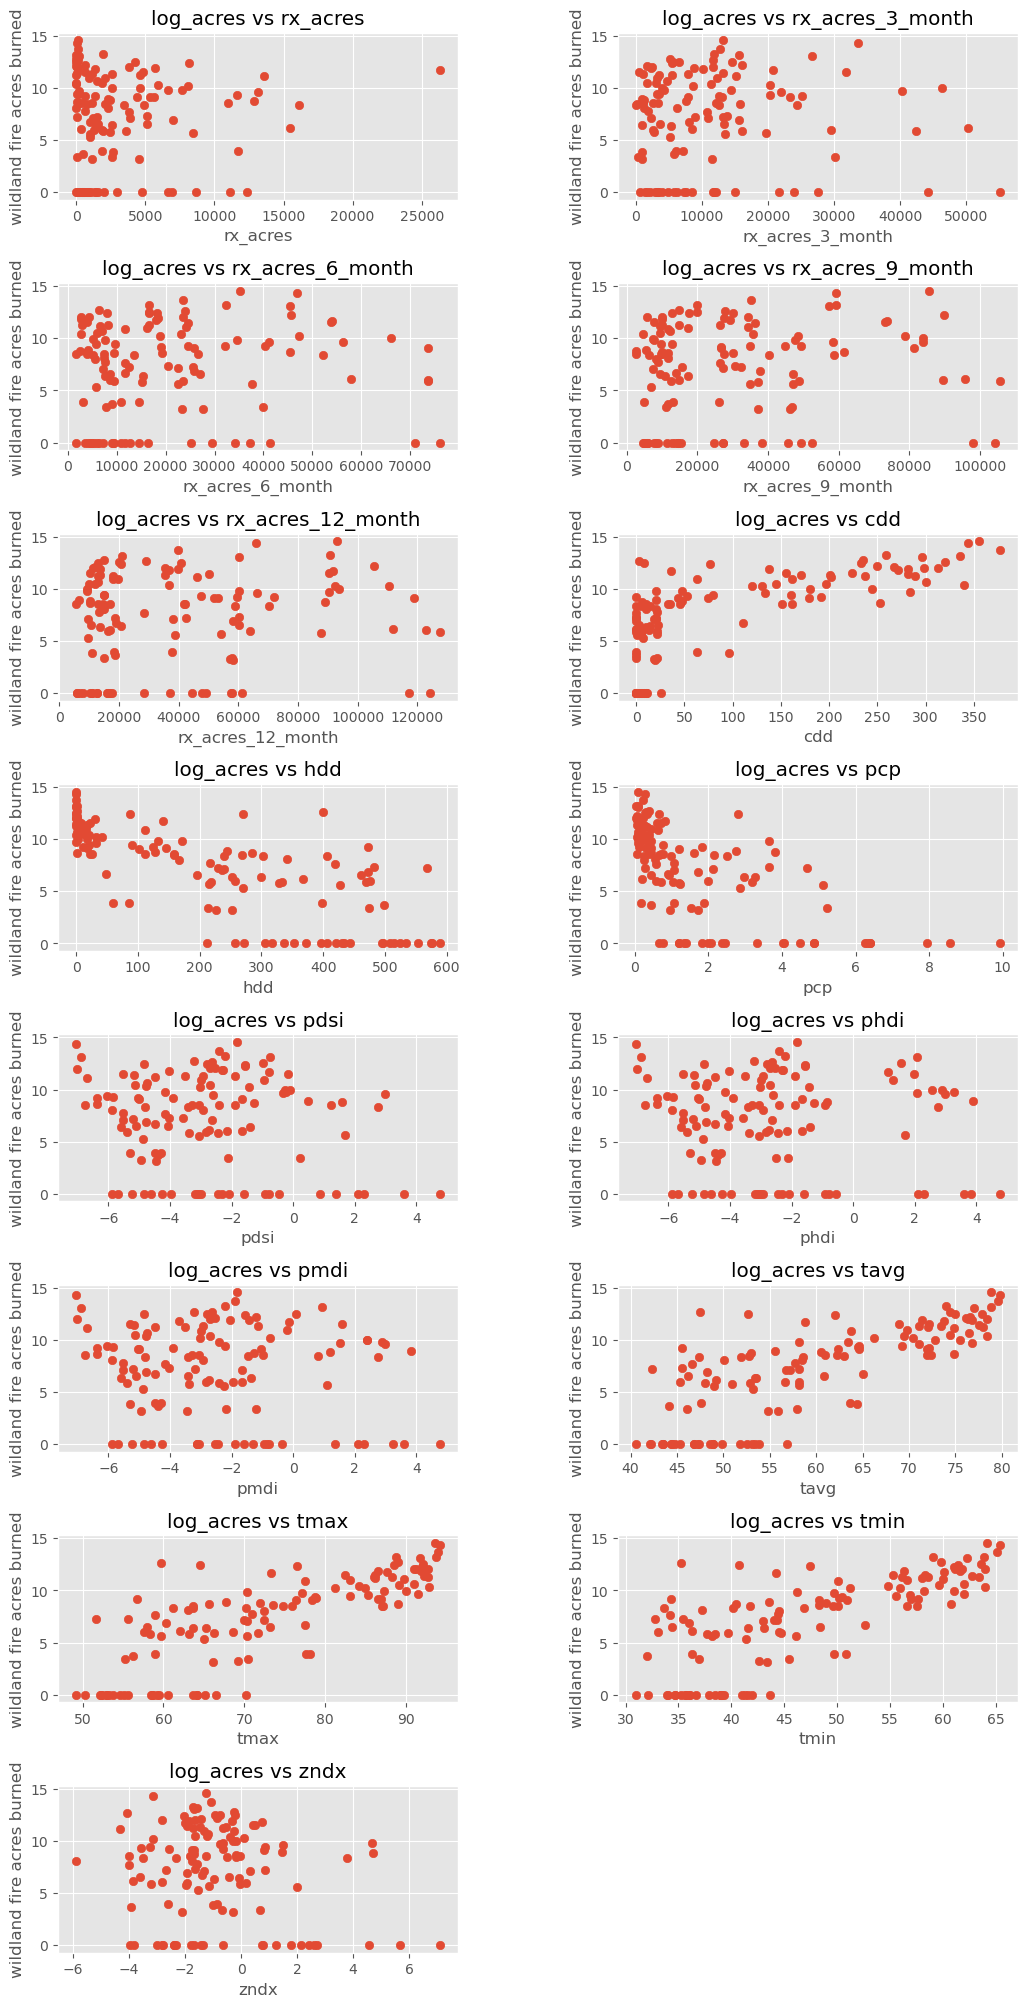

In [56]:
predictors = [ 'rx_acres', 'rx_acres_3_month', 'rx_acres_6_month','rx_acres_9_month', 'rx_acres_12_month', 'cdd', 'hdd', 'pcp', 'pdsi',
       'phdi', 'pmdi', 'tavg', 'tmax', 'tmin', 'zndx']
target = 'log_acres'
_ = scatter_plots(data, target, predictors)

In [57]:
mwu, t = run_stats(data, "log_acres", ["prescribed_5000", "prescribed_8000", "prescribed_10000"])
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_5000,MWU,1198.0,two-sided,0.881,0.020,0.490
prescribed_8000,MWU,761.0,two-sided,0.836,0.034,0.483
prescribed_10000,MWU,573.5,two-sided,0.816,0.043,0.478


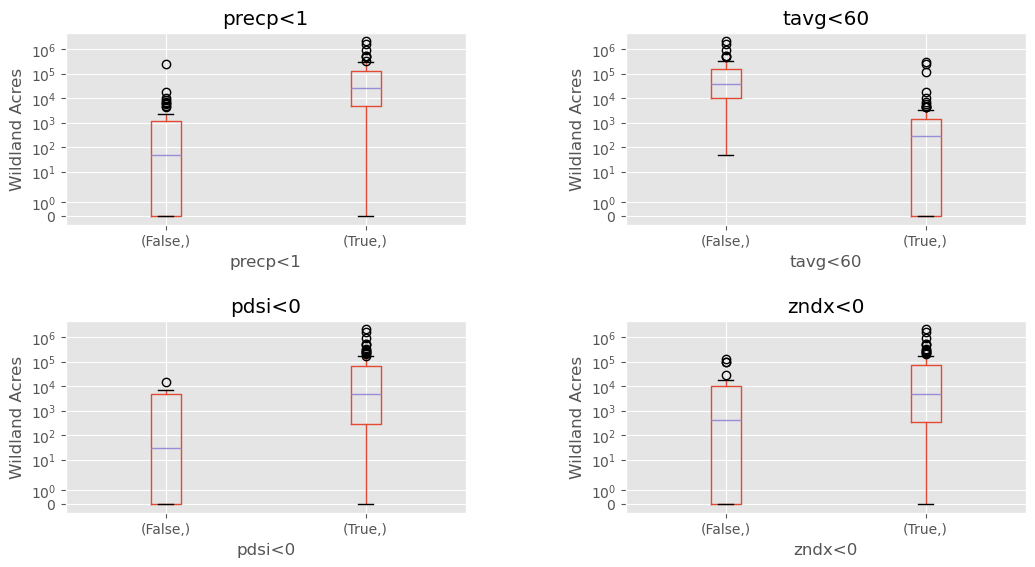

,,U-val,alternative,p-val,RBC,CLES
precp<1,MWU,3117.5,two-sided,0.000,-0.772,0.886
tavg<60,MWU,274.5,two-sided,0.000,0.847,0.077
pdsi<0,MWU,1007.5,two-sided,0.008,-0.449,0.724
zndx<0,MWU,1654.0,two-sided,0.012,-0.317,0.659


In [58]:
data["zndx<0"] = data['zndx']<0
data["zndx<-2"] = data['zndx']<-2
data["precp<1"] = data['pcp']< 1
data["tavg<60"] = data['tavg']<60
mwu, t = run_stats(data, "log_acres", ["precp<1","tavg<60", "pdsi<0", "zndx<0"])
fig = build_boxplots(data, target, predictors = ["precp<1","tavg<60", "pdsi<0","zndx<0"])
fig.savefig("figures/climate_bp.pdf")
display(mwu.round(3))

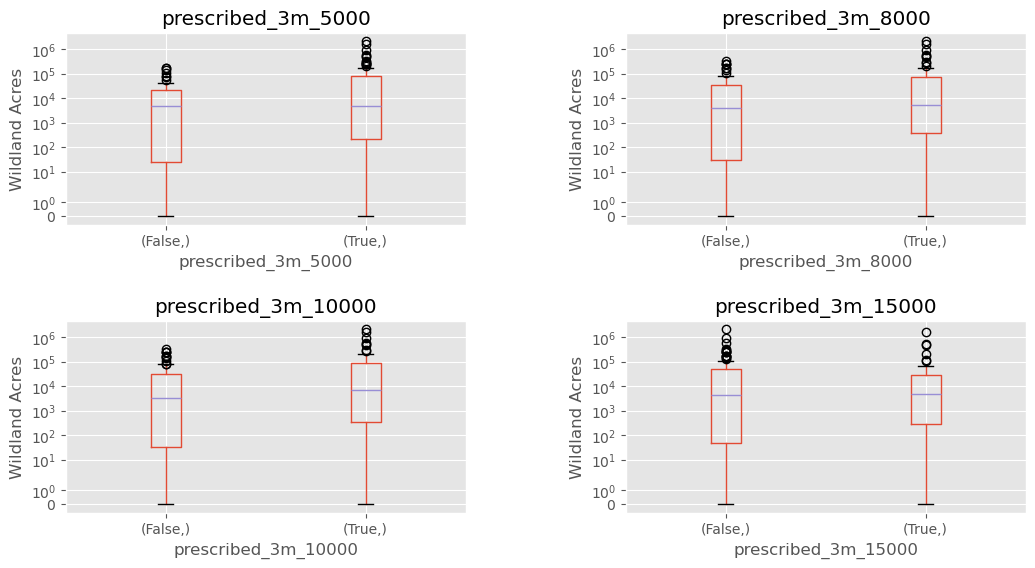

,,U-val,alternative,p-val,RBC,CLES
prescribed_3m_5000,MWU,1846.5,two-sided,0.251,-0.127,0.564
prescribed_3m_8000,MWU,2045.5,two-sided,0.197,-0.136,0.568
prescribed_3m_10000,MWU,2049.0,two-sided,0.158,-0.150,0.575
prescribed_3m_15000,MWU,1329.5,two-sided,0.953,-0.008,0.504


In [59]:
data["prescribed_3m_10000"] = data['rx_acres_3_month']>10000
data["prescribed_3m_15000"] = data['rx_acres_3_month']>15000
data["prescribed_3m_8000"] = data['rx_acres_3_month']>8000
data["prescribed_3m_5000"] = data['rx_acres_3_month']>5000
_ = build_boxplots(data, "log_acres", predictors = ["prescribed_3m_5000", "prescribed_3m_8000", "prescribed_3m_10000","prescribed_3m_15000" ])
mwu, t = run_stats(data, "log_acres", ["prescribed_3m_5000", "prescribed_3m_8000", "prescribed_3m_10000", "prescribed_3m_15000"])
display(mwu.round(3))

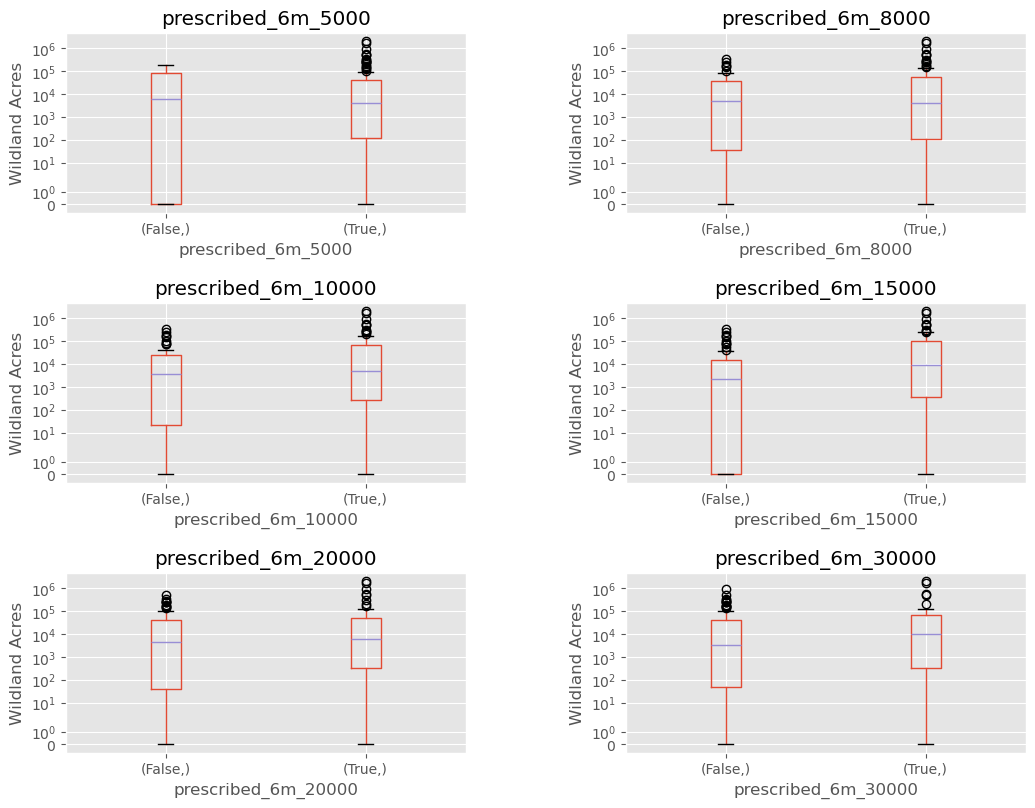

,,U-val,alternative,p-val,RBC,CLES
prescribed_6m_5000,MWU,882.5,two-sided,0.961,-0.008,0.504
prescribed_6m_8000,MWU,1602.0,two-sided,0.805,-0.028,0.514
prescribed_6m_10000,MWU,1947.5,two-sided,0.239,-0.127,0.564
prescribed_6m_15000,MWU,2267.5,two-sided,0.014,-0.260,0.630
prescribed_6m_20000,MWU,1872.0,two-sided,0.400,-0.091,0.546
prescribed_6m_30000,MWU,1404.0,two-sided,0.350,-0.118,0.559


In [60]:
data["prescribed_6m_10000"] = data['rx_acres_6_month']>10000
data["prescribed_6m_15000"] = data['rx_acres_6_month']>15000
data["prescribed_6m_20000"] = data['rx_acres_6_month']>20000
data["prescribed_6m_30000"] = data['rx_acres_6_month']>30000
data["prescribed_6m_8000"] = data['rx_acres_6_month']>8000
data["prescribed_6m_5000"] = data['rx_acres_6_month']>5000
_ = build_boxplots(data, "log_acres", predictors = ["prescribed_6m_5000", "prescribed_6m_8000", "prescribed_6m_10000", "prescribed_6m_15000", "prescribed_6m_20000", "prescribed_6m_30000"])
mwu, t = run_stats(data, "log_acres", ["prescribed_6m_5000", "prescribed_6m_8000", "prescribed_6m_10000", "prescribed_6m_15000", "prescribed_6m_20000", "prescribed_6m_30000"])
display(mwu.round(3))

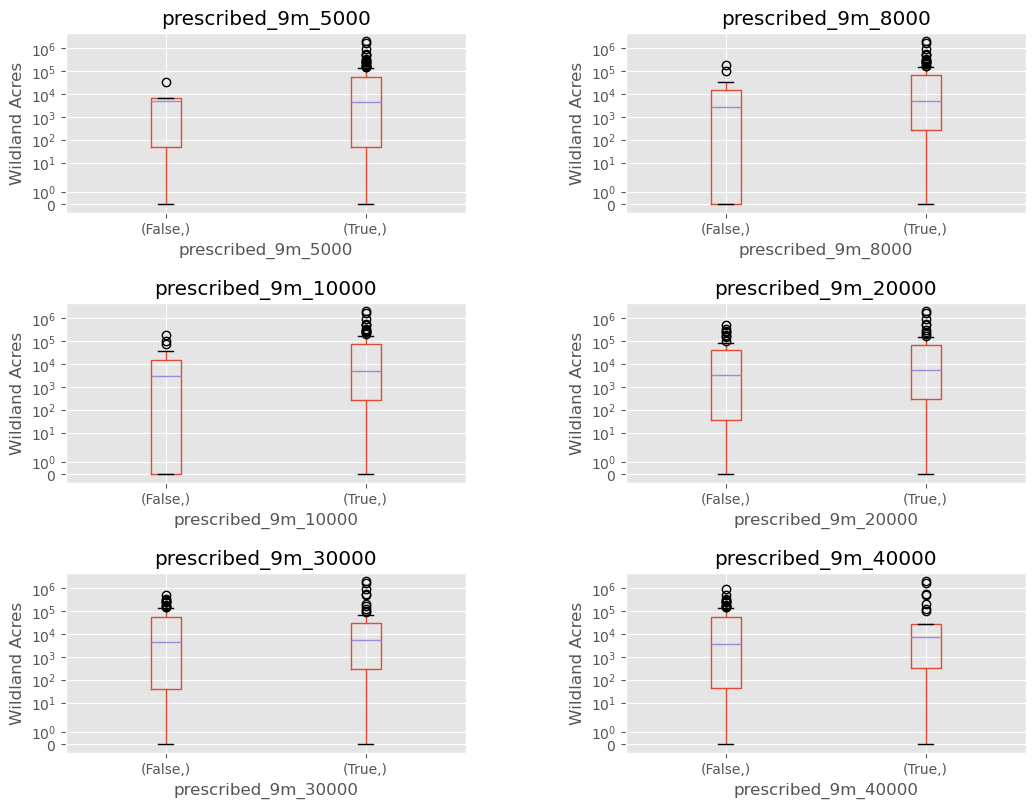

,,U-val,alternative,p-val,RBC,CLES
prescribed_9m_5000,MWU,329.5,two-sided,0.584,-0.146,0.573
prescribed_9m_8000,MWU,1102.0,two-sided,0.176,-0.200,0.600
prescribed_9m_10000,MWU,1478.0,two-sided,0.161,-0.177,0.589
prescribed_9m_20000,MWU,1965.0,two-sided,0.385,-0.092,0.546
prescribed_9m_30000,MWU,1822.0,two-sided,0.567,-0.062,0.531
prescribed_9m_40000,MWU,1505.0,two-sided,0.565,-0.069,0.534


In [61]:
data["prescribed_9m_10000"] = data['rx_acres_9_month']>10000
data["prescribed_9m_20000"] = data['rx_acres_9_month']>20000
data["prescribed_9m_30000"] = data['rx_acres_9_month']>30000
data["prescribed_9m_40000"] = data['rx_acres_9_month']>40000
data["prescribed_9m_8000"] = data['rx_acres_9_month']>8000
data["prescribed_9m_5000"] = data['rx_acres_9_month']>5000
_ = build_boxplots(data, "log_acres", predictors = ["prescribed_9m_5000", "prescribed_9m_8000", "prescribed_9m_10000", "prescribed_9m_20000", "prescribed_9m_30000", "prescribed_9m_40000"])
mwu, t = run_stats(data, "log_acres", ["prescribed_9m_5000", "prescribed_9m_8000", "prescribed_9m_10000",  "prescribed_9m_10000", "prescribed_9m_20000", "prescribed_9m_30000", "prescribed_9m_40000"])
display(mwu.round(3))

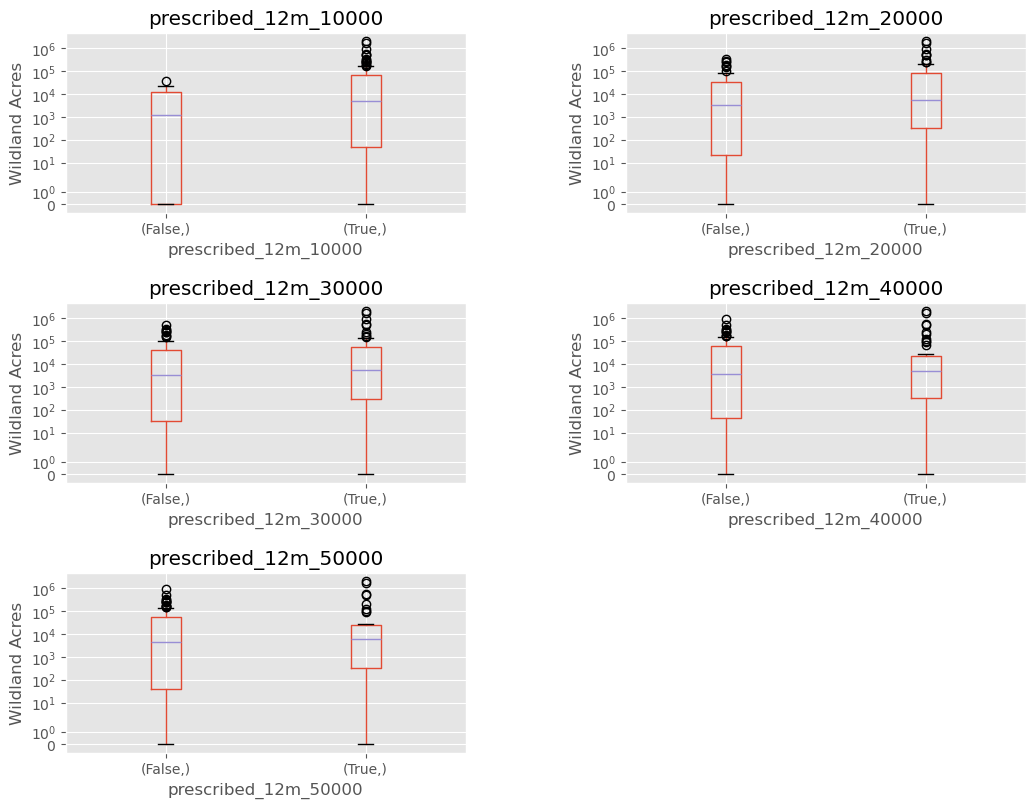

,,U-val,alternative,p-val,RBC,CLES
prescribed_12m_10000,MWU,749.0,two-sided,0.174,-0.249,0.625
prescribed_12m_20000,MWU,2045.0,two-sided,0.182,-0.141,0.571
prescribed_12m_30000,MWU,1965.5,two-sided,0.379,-0.093,0.547
prescribed_12m_40000,MWU,1758.5,two-sided,0.872,-0.018,0.509
prescribed_12m_50000,MWU,1659.0,two-sided,0.657,-0.050,0.525


In [62]:
data["prescribed_12m_40000"] = data['rx_acres_12_month']>40000
data["prescribed_12m_50000"] = data['rx_acres_12_month']>50000
data["prescribed_12m_30000"] = data['rx_acres_12_month']>30000
data["prescribed_12m_20000"] = data['rx_acres_12_month']>20000
data["prescribed_12m_10000"] = data['rx_acres_12_month']>10000
_ = build_boxplots(data, "log_acres", predictors = ["prescribed_12m_10000", "prescribed_12m_20000", "prescribed_12m_30000", "prescribed_12m_40000", "prescribed_12m_50000"])
mwu, t = run_stats(data, "log_acres", ["prescribed_12m_10000", "prescribed_12m_20000", "prescribed_12m_30000",  "prescribed_12m_40000", "prescribed_12m_50000"])
display(mwu.round(3))

# Chi-squared

In [63]:
# region vs year 
# get region for gdf, df
import pingouin as pg

In [64]:
def calculate_residuals(expected, observed): 
    total = sum(expected.sum())
    residual = expected.copy()
    for r in expected.index:
        for c in expected.columns:
            row_sum = sum([expected.at[r, col] for col in expected.columns])
            col_sum = sum([expected.at[ind, c] for ind in expected.index])
            residual.at[r,c] = (observed.at[r,c] - expected.at[r,c])/np.sqrt(expected.at[r,c]*(1-row_sum/total)*(1-col_sum/total))
    return residual

In [65]:
# wildfire
expected, observed, stats = pg.chi2_independence(df, x='region',
                                                 y='year')
display(stats)
display(expected)
display(observed)
display(calculate_residuals(expected,observed))
pct_less_than_5 = np.average([expected.at[r,c]<5 for r in expected.index for c in expected.columns])
print(pct_less_than_5)
pct_less_than_5 = np.average([observed.at[r,c]<5 for r in expected.index for c in expected.columns])
print(pct_less_than_5)


/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pingouin/contingency.py:150: UserWarning: Low count on observed frequencies.
  warnings.warn("Low count on {} frequencies.".format(name))
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pingouin/contingency.py:150: UserWarning: Low count on expected frequencies.
  warnings.warn("Low count on {} frequencies.".format(name))


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,126.836233,63.0,3.401342e-06,0.094222,0.438257
1,cressie-read,0.666667,125.660874,63.0,4.644815e-06,0.093784,0.433534
2,log-likelihood,0.000000,126.120913,63.0,4.112740e-06,0.093956,0.435383
3,freeman-tukey,-0.500000,129.220341,63.0,1.794533e-06,0.095103,0.447835
4,mod-log-likelihood,-1.000000,135.235501,63.0,3.427676e-07,0.097291,0.471946
5,neyman,-2.000000,160.079003,63.0,2.117288e-10,0.105851,0.569158


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
region,,,,,,,,,,
Central Coast,23.557570,11.862322,16.039196,25.729544,71.173934,50.122489,43.773640,42.771191,30.908868,25.061244
Central Valley,29.913278,15.062714,20.366487,32.671240,90.376286,63.645272,55.583537,54.310632,39.247918,31.822636
Desert,17.409113,8.766291,11.853013,19.014209,52.597746,37.040666,32.348849,31.608035,22.841744,18.520333
Multiple,2.970603,1.495835,2.022538,3.244488,8.975012,6.320431,5.519843,5.393435,3.897599,3.160216
North Coast,11.606075,5.844194,7.902009,12.676139,35.065164,24.693778,21.565899,21.072024,15.227829,12.346889
Shasta Cascades,23.626654,11.897109,16.086232,25.804998,71.382656,50.269476,43.902009,42.896619,30.999510,25.134738
Sierras,18.721705,9.427242,12.746693,20.447820,56.563449,39.833415,34.787849,33.991181,24.563939,19.916707
South Coast,13.195002,6.644292,8.983831,14.411563,39.865752,28.074473,24.518373,23.956884,17.312592,14.037237


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
region,,,,,,,,,,
Central Coast,20,5,13,26,66,68,58,48,18,19
Central Valley,25,11,16,45,93,59,53,59,37,35
Desert,28,3,8,5,68,31,40,31,23,15
Multiple,3,2,1,1,5,6,2,13,7,3
North Coast,20,4,13,14,33,25,15,16,16,12
Shasta Cascades,18,19,23,23,67,53,43,36,33,27
Sierras,15,13,13,27,60,31,29,31,31,21
South Coast,12,14,9,13,34,27,22,22,20,18


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
region,,,,,,,,,,
Central Coast,-0.832396,-2.222141,-0.851778,0.060759,-0.755427,2.995780,2.523585,0.936756,-2.667941,-1.378267
Central Valley,-1.048969,-1.200415,-1.116643,2.527264,0.349545,-0.710278,-0.418171,0.766572,-0.423919,0.659255
Desert,2.809992,-2.117353,-1.224515,-3.570108,2.550071,-1.147847,1.539031,-0.123523,0.037089,-0.907719
Multiple,0.017867,0.424075,-0.744417,-1.309796,-1.507579,-0.139478,-1.621874,3.539827,1.665542,-0.094634
North Coast,2.665752,-0.810560,1.939298,0.403680,-0.409265,0.069649,-1.580871,-1.233341,0.216610,-0.107063
Shasta Cascades,-1.314978,2.297352,1.935415,-0.629421,-0.639147,0.457026,-0.159818,-1.234104,0.412968,0.423646
Sierras,-0.957302,1.271846,0.078045,1.618202,0.551601,-1.627278,-1.128683,-0.589111,1.462307,0.270799
South Coast,-0.358133,3.050873,0.005804,-0.406178,-1.096970,-0.230620,-0.572194,-0.449043,0.711411,1.154167


0.075
0.1


In [66]:
color_dict = {"Central Coast":'#E24A33',
              "Central Valley": '#348ABD',
              "Desert":'#988ED5',
              "North Coast":'#777777',
              "Shasta Cascades":'#FBC15E',
              "Sierras":'#8EBA42',
              "South Coast":'#FFB5B8',
              "Multiple":"#000000"}

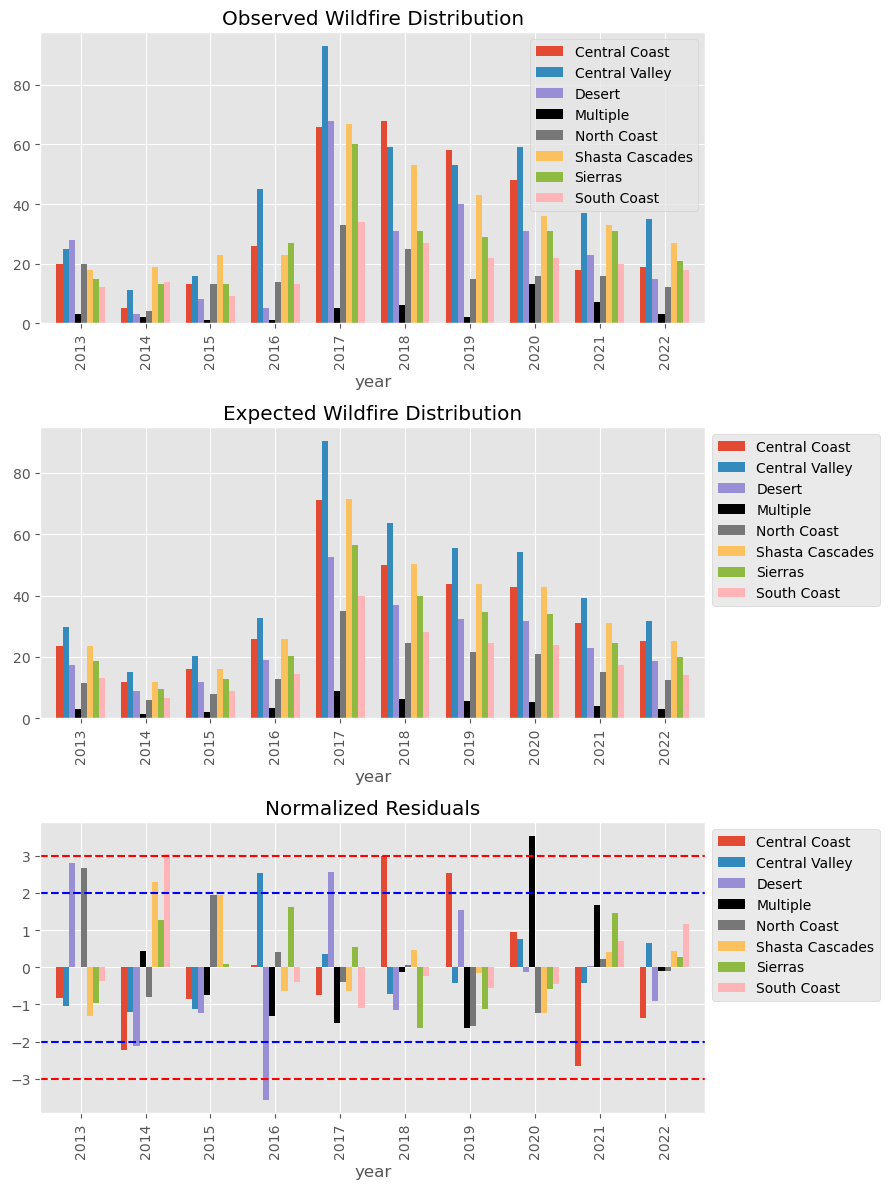

In [67]:
fig, axs = plt.subplots(3, 1, figsize=(9,12))
observed.T.plot.bar(ax=axs[0], width=0.75, color=color_dict, title="Observed Wildfire Distribution").legend(bbox_to_anchor=(1,1))
expected.T.plot.bar(ax=axs[1], width=0.75,color=color_dict, title= "Expected Wildfire Distribution").legend(bbox_to_anchor=(1,1))
calculate_residuals(expected,observed).T.plot.bar(ax=axs[2], width=0.75, color=color_dict,title="Normalized Residuals")
axs[2].axhline(y = 2, color = 'b', linestyle = '--')
axs[2].axhline(y = -2, color = 'b', linestyle = '--')
axs[2].axhline(y = 3, color = 'r', linestyle = '--')
axs[2].axhline(y = -3, color = 'r', linestyle = '--')
plt.legend(bbox_to_anchor=(1,1))
fig.subplots_adjust(hspace=0.5)
plt.tight_layout()
plt.savefig("figures/wildfire_chi.pdf")
plt.show()

In [68]:
gdf.columns

Index(['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'TREATMENT_ID',
       'TREATMENT_NAME', 'TREATMENT_TYPE', 'END_DATE', 'TREATED_AC',
       'GIS_ACRES', 'RX_CONSUM', 'PRE_CON_CLASS', 'POST_CON_CLASS',
       'SHAPE_Length', 'SHAPE_Area', 'geometry', 'year', 'lon_center',
       'lat_center', 'acres_decimal', 'county', 'region', 'month'],
      dtype='object')

In [69]:
# prescribed fire
expected, observed, stats = pg.chi2_independence(gdf, x='region',
                                                 y='year')
display(stats)
display(expected)
display(observed)
display(calculate_residuals(expected,observed))
pct_less_than_5 = np.average([expected.at[r,c]<5 for r in expected.index for c in expected.columns])
print(pct_less_than_5)
pct_less_than_5 = np.average([observed.at[r,c]<5 for r in expected.index for c in expected.columns])
print(pct_less_than_5)

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pingouin/contingency.py:150: UserWarning: Low count on observed frequencies.
  warnings.warn("Low count on {} frequencies.".format(name))
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pingouin/contingency.py:150: UserWarning: Low count on expected frequencies.
  warnings.warn("Low count on {} frequencies.".format(name))


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,382.960351,54.0,4.303164e-51,0.124421,0.996490
1,cressie-read,0.666667,376.391024,54.0,7.346776e-50,0.123349,0.995855
2,log-likelihood,0.000000,371.262582,54.0,6.695192e-49,0.122506,0.995287
3,freeman-tukey,-0.500000,374.251276,54.0,1.848224e-49,0.122998,0.995626
4,mod-log-likelihood,-1.000000,383.459137,54.0,3.468068e-51,0.124502,0.996534
5,neyman,-2.000000,425.103417,54.0,4.516182e-59,0.131089,0.998841


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
region,,,,,,,,,,
Central Coast,6.370119,5.989813,6.940577,2.899830,10.648557,22.818336,52.767402,40.217317,28.095076,19.252971
Central Valley,22.067912,20.750424,24.044143,10.045840,36.889643,79.049236,182.801358,139.324278,97.329372,66.697793
Desert,5.492602,5.164686,5.984477,2.500364,9.181664,19.674994,45.498423,34.677177,24.224836,16.600776
North Coast,10.660199,10.023769,11.614844,4.852777,17.820034,38.185787,88.304633,67.302450,47.016250,32.219258
Shasta Cascades,42.868300,40.308998,46.707252,19.514674,71.660441,153.558089,355.103080,270.646131,189.068397,129.564637
Sierras,40.755760,38.322581,44.405530,18.552995,68.129032,145.990783,337.603687,257.308756,179.751152,123.179724
South Coast,5.785108,5.439728,6.303177,2.633519,9.670628,20.722775,47.921416,36.523890,25.514916,17.484841


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
region,,,,,,,,,,
Central Coast,4,5,8,8,23,13,38,15,36,46
Central Valley,15,32,34,12,37,75,253,124,61,36
Desert,6,1,5,4,9,12,38,45,29,20
North Coast,19,15,22,12,29,31,60,49,41,50
Shasta Cascades,42,34,49,7,57,198,415,270,159,88
Sierras,46,37,21,11,56,138,261,316,220,148
South Coast,2,2,7,7,13,13,45,27,45,17


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
region,,,,,,,,,,
Central Coast,-0.978244,-0.420884,0.419543,3.091799,3.988215,-2.240522,-2.436714,-4.570219,1.651031,6.577409
Central Valley,-1.673633,2.744336,2.261924,0.679640,0.020443,-0.530123,6.645401,-1.593346,-4.353187,-4.330903
Desert,0.224762,-1.900589,-0.418417,0.975684,-0.062954,-1.879690,-1.327906,2.007860,1.070391,0.897131
North Coast,2.706752,1.663893,3.233970,3.407059,2.838684,-1.289441,-3.672600,-2.608333,-0.988096,3.438309
Shasta Cascades,-0.163491,-1.223818,0.414201,-3.460934,-2.159509,4.626485,4.508707,-0.053420,-2.864935,-4.662839
Sierras,1.001161,-0.260121,-4.287165,-2.117826,-1.811471,-0.843422,-5.846481,4.919895,3.888260,2.823127
South Coast,-1.635612,-1.531293,0.288905,2.771298,1.125507,-1.845056,-0.504683,-1.807080,4.260737,-0.124826


0.05714285714285714
0.07142857142857142


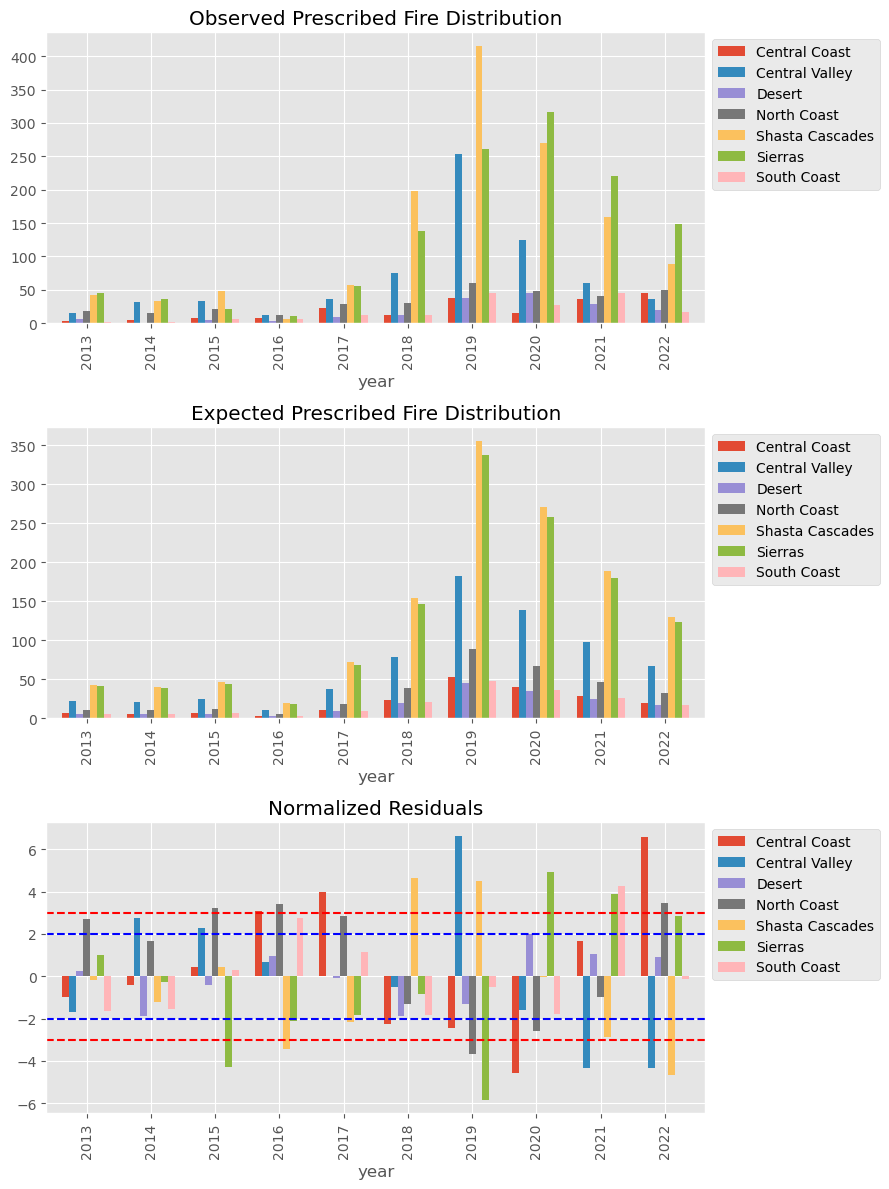

In [70]:
fig, axs = plt.subplots(3, 1, figsize=(9,12))
observed.T.plot.bar(ax=axs[0], width=0.75, color=color_dict, title="Observed Prescribed Fire Distribution").legend(bbox_to_anchor=(1,1))
ax[0].set_ylim([0,450])
expected.T.plot.bar(ax=axs[1], width=0.75,color=color_dict, title= "Expected Prescribed Fire Distribution").legend(bbox_to_anchor=(1,1))
ax[1].set_ylim([0,450])
calculate_residuals(expected,observed).T.plot.bar(ax=axs[2], width=0.75, color=color_dict,title="Normalized Residuals")
axs[2].axhline(y = 2, color = 'b', linestyle = '--')
axs[2].axhline(y = -2, color = 'b', linestyle = '--')
axs[2].axhline(y = 3, color = 'r', linestyle = '--')
axs[2].axhline(y = -3, color = 'r', linestyle = '--')
plt.legend(bbox_to_anchor=(1,1))
fig.subplots_adjust(hspace=0.5)
plt.tight_layout()
plt.savefig("figures/rx_chi.pdf")
plt.show()

Anova
- climate vars between regions
1. get region average for each month/year
 - for each region, subset it to the columns from the sheet
 - take average
 - get new sheet with regions for cols, averages for vals
2. Anova between the regions, post-hoc t-tests, barcharts 

In [71]:
climate_dfs = pd.read_excel("data/raw/noaa_climate/climate_data.xlsx", sheet_name=None, index_col=0)
for sheet in climate_dfs:
    print(sheet)
    climate_dfs[sheet].index = pd.to_datetime(climate_dfs[sheet].index)

tavg
tmax
tmin
pcp
cdd
hdd
pdsi
phdi
pmdi
zndx
